# 01. Air quality in Bishkek: exploratory analysis
Question: how polluted is Bishkek's air, when is it worst, and how does it relate to the weather?

**Data:** PM2.5 from the US Embassy Bishkek monitor (AirNow), one reading per day at 21:00 local time, joined with weather at the same hour (Open-Meteo). PM2.5 is in µg/m³.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/bishkek_pm25.csv", parse_dates=["date"], index_col="date")
df.head()

,pm25,temperature_2m,relative_humidity_2m,wind_speed_10m
date,,,,
2023-01-01,27.0,-7.2,62,11.5
2023-01-02,65.0,-3.9,43,6.9
2023-01-03,44.0,-2.2,64,3.2
2023-01-04,18.0,-1.2,81,9.7
2023-01-05,36.0,-0.2,55,13.2


## Coverage and data quality

In [2]:
print(df.shape, df.index.min().date(), "to", df.index.max().date())
print("Missing values:", df.isna().sum().sum())
full = pd.date_range(df.index.min(), df.index.max())
print(f"Days with a reading: {len(df)} of {len(full)} ({len(df) / len(full):.0%})")
df.describe().T.round(1)

(743, 4) 2023-01-01 to 2025-03-03
Missing values: 0
Days with a reading: 743 of 793 (94%)


,count,mean,std,min,25%,50%,75%,max
pm25,743.0,28.5,50.5,0.0,1.1,9.0,33.0,401.0
temperature_2m,743.0,10.0,11.0,-21.7,0.8,10.2,18.8,31.2
relative_humidity_2m,743.0,60.0,19.5,15.0,44.0,59.0,76.0,100.0
wind_speed_10m,743.0,7.4,4.1,0.2,4.7,6.7,9.2,31.3


## PM2.5 over time

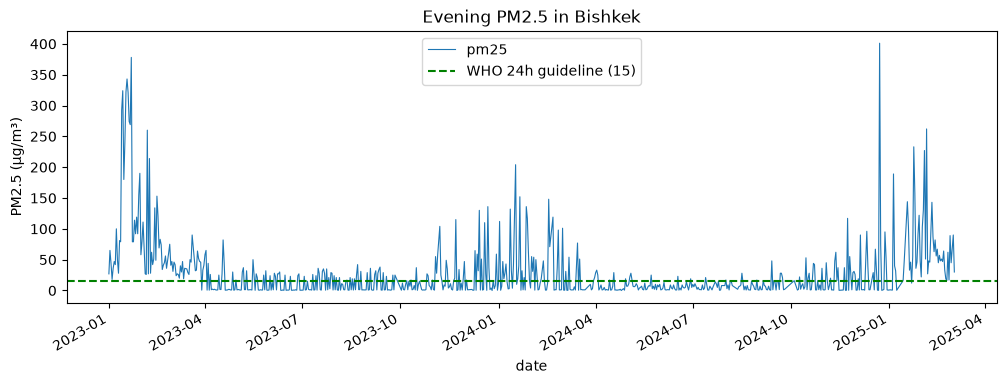

In [3]:
ax = df["pm25"].plot(figsize=(12, 4), lw=0.8)
ax.axhline(15, color="green", ls="--", label="WHO 24h guideline (15)")
ax.set(ylabel="PM2.5 (µg/m³)", title="Evening PM2.5 in Bishkek")
ax.legend()
plt.show()

## Distribution
The distribution is heavily right-skewed, so the mean is much higher than the median.

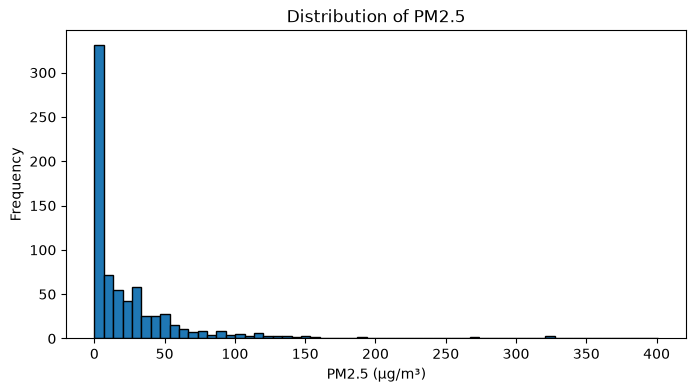

mean: 28.5 median: 9.0 max: 401.0


In [4]:
df["pm25"].plot.hist(bins=60, edgecolor="black", figsize=(8, 4))
plt.xlabel("PM2.5 (µg/m³)")
plt.title("Distribution of PM2.5")
plt.show()
print("mean:", round(df.pm25.mean(), 1), "median:", df.pm25.median(), "max:", df.pm25.max())

## Seasonality: average PM2.5 by month

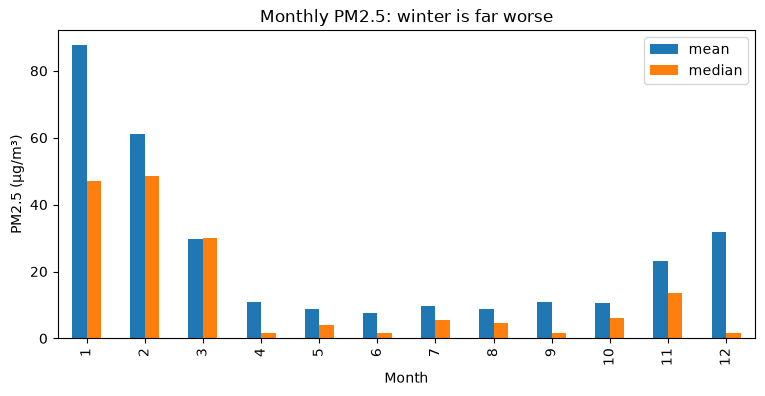

date,1,2,3,4,5,6,7,8,9,10,11,12
mean,87.7,61.1,29.7,10.8,8.8,7.5,9.8,8.7,10.9,10.7,23.1,31.7
median,47.0,48.5,30.0,1.6,4.0,1.6,5.5,4.5,1.5,6.0,13.5,1.5


In [5]:
monthly = df.groupby(df.index.month)["pm25"].agg(["mean", "median"])
monthly.plot.bar(figsize=(9, 4))
plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Monthly PM2.5: winter is far worse")
plt.show()
monthly.round(1).T

## Relationship with weather

temperature_2m         -0.47
wind_speed_10m         -0.24
relative_humidity_2m    0.11
Name: pm25, dtype: float64


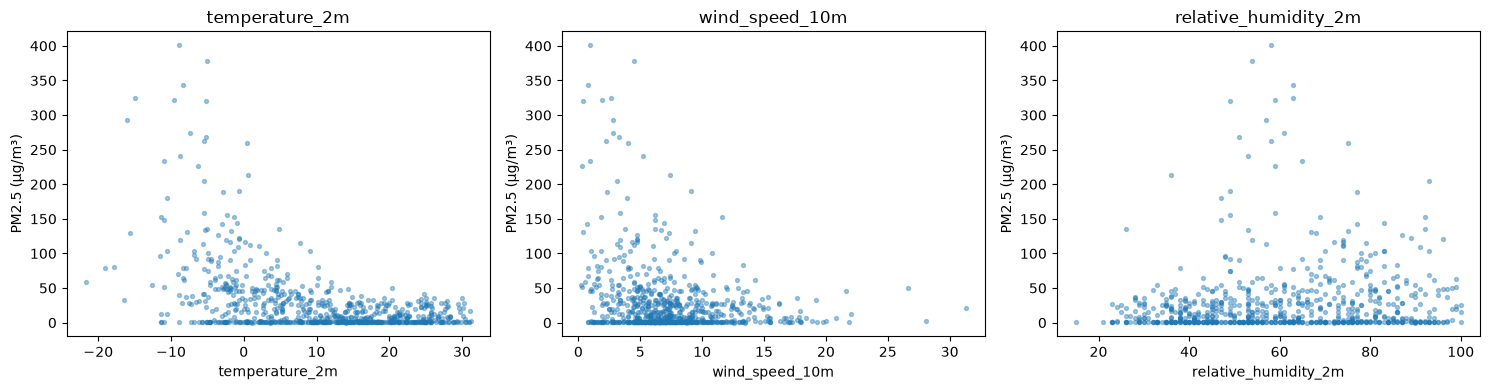

In [6]:
weather = ["temperature_2m", "wind_speed_10m", "relative_humidity_2m"]
print(df[["pm25"] + weather].corr()["pm25"].drop("pm25").round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, weather):
    ax.scatter(df[col], df["pm25"], s=8, alpha=0.4)
    ax.set(xlabel=col, ylabel="PM2.5 (µg/m³)", title=col)
plt.tight_layout()
plt.show()